# FAQ de pandas — repaso

Este cuaderno responde **las dudas que más se repiten** al trabajar con pandas.
Cada entrada tiene la misma forma:

1. **Pregunta**, tal como suele aparecer en clase.
2. **Cómo se resuelve**, con el razonamiento antes del código.
3. **Pasos numerados**: cada paso es una celda pequeña que puedes ejecutar sola.
4. **Uso real**: cómo se escribe de verdad en un proyecto.
5. **Parámetros** de cada función usada.
6. **Trampa**: el error concreto que provoca el síntoma.

## Nota para comentar en clase: ejercicios 04 y 05 ya entregados

- **04 Apply:** el ejercicio incluye una pista con `applymap`, método deprecado desde pandas 2.1. Para aplicar una función elemento a elemento a un DataFrame, usa `DataFrame.map`. El notebook entregado no se modifica; esta es la alternativa vigente.
- **05 Merge:** el título “Append” es terminología antigua, pero la pista ya resuelve la operación con `pd.concat`, que es la forma actual. `DataFrame.append` se eliminó en pandas 2.0.

## Reglas de este cuaderno

- Funciona en **pandas 2.2 y pandas 3.x**. No se usa nada que esté deprecado.
- **Nunca `inplace=True`**. En pandas 3.1 está deprecado en los métodos que
  devuelven una copia (`drop`, `rename`, `sort_values`, `set_index`,
  `reset_index`, `dropna`, `drop_duplicates`...). Se reasigna el resultado.
- **Nunca indexación encadenada** (`df["col"][mask] = x`). En pandas 3.0 no
  funciona: se escribe en una copia temporal y el cambio se pierde. Se usa
  `df.loc[mask, "col"] = x`.
- Datos **locales**: los mismos `datasets/` de los ejercicios seleccionados.
  No se descarga nada.
- El detalle de los cambios de versión está en
  [`20-pandas-3-novedades.md`](../../01-teoria/20-pandas-3-novedades.md).

## Cómo usar el cuaderno

Ejecuta primero la celda de preparación. Después ve a la duda que tengas:
cada entrada es independiente. Si un paso te da un error inesperado, lee el
apartado **Trampa** de esa entrada antes de tocar el código.

---
# Preparación

Cargamos los tres conjuntos que se usan en este bloque y fijamos la salida para
que no ocupe media pantalla.

In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 30)

# Comprobamos que los ficheros están donde esperamos antes de leerlos.
for rel in [
    "datasets/Chipotle/chipotle.tsv",
    "datasets/Euro12/Euro_2012_stats_TEAM.csv",
    "datasets/Titanic_Desaster/train.csv",
]:
    assert Path(rel).exists(), f"Falta {rel}: ejecuta el cuaderno desde ejercicios_seleccionados/"

chipo = pd.read_csv("datasets/Chipotle/chipotle.tsv", sep="\t")
titanic = pd.read_csv("datasets/Titanic_Desaster/train.csv")
euro12 = pd.read_csv("datasets/Euro12/Euro_2012_stats_TEAM.csv")

print("pandas:", pd.__version__)
print("chipo:", chipo.shape, "| titanic:", titanic.shape, "| euro12:", euro12.shape)

pandas: 2.3.3
chipo: (4622, 5) | titanic: (891, 12) | euro12: (16, 35)


---
# A. Saber qué tengo delante (cuaderno 01)

Antes de seleccionar nada hay que saber **qué forma tiene** el DataFrame, **qué
tipo** tiene cada columna y **dónde hay huecos**. Casi todos los errores de las
siguientes secciones vienen de saltarse este paso.

## F01 — ¿Cómo cargo un fichero y sé qué tengo delante?

**Pregunta.** «He cargado el fichero y no sé si está bien. ¿Qué miro primero?»

**Cómo se resuelve.** Se miran cuatro cosas, en este orden: **forma**
(`shape`), **primeras filas** (`head`), **tipos y nulos** (`info`) y **nombres de
columnas** (`columns`). Si los tipos no son los que esperas, no sigas: cualquier
operación posterior dará resultados raros.

El fichero de Chipotle es un **TSV** (separado por tabuladores), no un CSV.
Si lo lees sin `sep="\t"` te sale una sola columna con todo dentro.

In [2]:
# Paso 1 — Leer indicando el separador correcto (tabulador)
chipo_tsv = pd.read_csv("datasets/Chipotle/chipotle.tsv", sep="\t")
chipo_tsv.head(3)

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39


In [3]:
# Paso 2 — Forma: (filas, columnas). Es lo primero que se comprueba.
print("Filas:", chipo_tsv.shape[0])
print("Columnas:", chipo_tsv.shape[1])

Filas: 4622
Columnas: 5


In [4]:
# Paso 3 — Nombres exactos y en orden. Se copian de aquí, nunca se escriben a mano.
list(chipo_tsv.columns)

['order_id', 'quantity', 'item_name', 'choice_description', 'item_price']

In [5]:
# Paso 4 — Tipos y nulos de un vistazo
chipo_tsv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4622 entries, 0 to 4621
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   order_id            4622 non-null   int64 
 1   quantity            4622 non-null   int64 
 2   item_name           4622 non-null   object
 3   choice_description  3376 non-null   object
 4   item_price          4622 non-null   object
dtypes: int64(2), object(3)
memory usage: 180.7+ KB


In [6]:
# Paso 5 — Tipo de una columna concreta
print(chipo_tsv["quantity"].dtype)
print(chipo_tsv["item_price"].dtype)

int64
object


**Uso real.** Una función de auditoría que se ejecuta nada más cargar:

```python
def auditar(df):
    print(df.shape)
    print(df.dtypes.to_string())
    print(df.isna().sum()[lambda s: s > 0].to_string())
    return df.head()
```

In [7]:
# Uso real
def auditar(df, nombre="datos"):
    print(f"--- {nombre}: {df.shape[0]} filas x {df.shape[1]} columnas")
    huecos = df.isna().sum()
    print(huecos[huecos > 0].to_string() or "sin huecos")
    return df.head(3)

auditar(chipo_tsv, "chipo")

--- chipo: 4622 filas x 5 columnas
choice_description    1246


,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39


**Parámetros que necesitas conocer.**

| Función / atributo | Parámetro | Qué significa |
|---|---|---|
| `pd.read_csv` | `filepath_or_buffer` | Ruta del fichero (o URL). |
| | `sep` | Separador de campos. `","` por defecto; `"\t"` para TSV. |
| | `header` | Fila que contiene los nombres. `0` = primera; `None` = no hay cabecera. |
| | `names` | Lista de nombres si el fichero no trae cabecera. |
| | `usecols` | Leer solo algunas columnas: ahorra memoria. |
| | `dtype` | Forzar el tipo al leer, p. ej. `{"quantity": "int32"}`. |
| | `na_values` | Qué textos se convierten en `NaN`, p. ej. `["?", "N/A"]`. |
| | `nrows` | Leer solo las N primeras filas (para mirar antes de cargar todo). |
| `df.head` | `n` | Número de filas. Por defecto 5. |
| `df.shape` | — | Atributo, no función. Devuelve `(filas, columnas)`. |
| `df.info` | `verbose` | `True` muestra más detalle del uso de memoria. |
| | `show_counts` | Mostrar el recuento de valores no nulos. |
| `df.dtypes` | — | Atributo. Una entrada por columna. |

> **Trampa.** `read_csv` sin `sep="\t"` no da error: devuelve un DataFrame con
> una única columna llamada `order_id\tquantity\titem_name...`. Si ves una sola
> columna con tabuladores dentro, el separador está mal. No sigas trabajando con
> ese DataFrame.

## F02 — ¿Por qué el precio es texto y cómo lo convierto a número?

**Pregunta.** «Quiero sumar `item_price` y me concatena los textos / me da error.»

**Cómo se resuelve.** `$2.39 ` no es un número: es texto con un símbolo y un
espacio. Hay que limpiar **primero** y convertir **después**. El orden importa:
`astype(float)` directamente sobre `"$2.39 "` lanza `ValueError`.

Se hace en tres pasos: quitar el símbolo, quitar los espacios y convertir. Al
final se guarda el resultado reasignando, sin `inplace`.

In [8]:
# Paso 1 — Guardamos la columna tal cual está y miramos qué hay dentro
crudo = chipo["item_price"]
crudo.head(5).tolist()

['$2.39 ', '$3.39 ', '$3.39 ', '$2.39 ', '$16.98 ']

In [9]:
# Paso 2 — Quitar el símbolo $ (regex=False: no es una expresión regular)
sin_simbolo = crudo.str.replace("$", "", regex=False)
sin_simbolo.head(3)

0    2.39 
1    3.39 
2    3.39 
Name: item_price, dtype: object

In [10]:
# Paso 3 — Quitar los espacios de los extremos
limpio = sin_simbolo.str.strip()
limpio.head(3)

0    2.39
1    3.39
2    3.39
Name: item_price, dtype: object

In [11]:
# Paso 4 — Convertir a número decimal
precio = limpio.astype(float)
print(precio.dtype)
precio.describe()

float64


count    4622.000000
mean        7.464336
std         4.245557
min         1.090000
25%         3.390000
50%         8.750000
75%         9.250000
max        44.250000
Name: item_price, dtype: float64

In [12]:
# Paso 5 — Guardar en un DataFrame nuevo (sin inplace)
chipo_limpio = chipo.assign(item_price=precio)
print(chipo_limpio["item_price"].dtype)
chipo_limpio["item_price"].head(3)

float64


0    2.39
1    3.39
2    3.39
Name: item_price, dtype: float64

**Uso real.** En una línea, con `to_numeric` que además convierte en `NaN` lo
que no se pueda leer en vez de romper:

```python
chipo_limpio = chipo.assign(
    item_price=pd.to_numeric(
        chipo["item_price"].str.replace("$", "", regex=False).str.strip(),
        errors="coerce",
    )
)
```

In [13]:
# Uso real
chipo_limpio = chipo.assign(
    item_price=pd.to_numeric(
        chipo["item_price"].str.replace("$", "", regex=False).str.strip(),
        errors="coerce",
    )
)
print("ingresos totales:", round(chipo_limpio["item_price"].sum(), 2))

ingresos totales: 34500.16


**Parámetros que necesitas conocer.**

| Función / método | Parámetro | Qué significa |
|---|---|---|
| `Series.str.replace` | `pat` | Texto a buscar. |
| | `repl` | Texto de sustitución. `""` borra. |
| | `regex` | `True` si `pat` es expresión regular. **Ponlo siempre explícito.** |
| | `n` | Máximo de sustituciones por elemento. `-1` = todas. |
| | `case` | Distinguir mayúsculas. |
| `Series.str.strip` | `to_strip` | Caracteres a quitar en los extremos. Por defecto, espacios. |
| `Series.astype` | `dtype` | Tipo destino: `float`, `int`, `"category"`, `"string"`. |
| | `errors` | `"raise"` (falla) o `"ignore"`. Preferible `to_numeric(errors="coerce")`. |
| `pd.to_numeric` | `arg` | Serie o columna a convertir. |
| | `errors` | `"raise"`, `"coerce"` (lo inválido → `NaN`) o `"ignore"`. |
| `df.assign` | `**kwargs` | Columnas nuevas o sustituidas: `assign(col=serie)`. Devuelve copia. |

> **Trampa.** `astype(float)` sobre `"$2.39 "` falla; no es un tipo de cambio de
> moneda, es texto. Y ojo: si usas `str.replace` sin `regex=False` en pandas 2.2
> funciona con `"$"`, pero `"$"` **sí** es un ancla de expresión regular. Sé
> explícito siempre.

---
# B. Seleccionar y filtrar (cuaderno 02)

Aquí está el 80 % de las dudas. La clave es una sola: **`df[...]` no hace
siempre lo mismo**. Lo que hace depende de lo que pongas dentro de los
corchetes.

## F03 — `df[...]` filtra filas o elige columnas, ¿cómo sé cuál?

**Pregunta.** «¿Por qué unas veces `df["algo"]` devuelve una columna y otras
veces filtra filas?»

**Cómo se resuelve.** pandas decide por el **tipo** de lo que hay dentro:

| Dentro de los corchetes | Resultado |
|---|---|
| un texto: `df["Age"]` | una **columna** (`Series`) |
| una lista de textos: `df[["Age", "Fare"]]` | varias **columnas** (`DataFrame`) |
| una Serie de `True`/`False`: `df[mask]` | **filas** filtradas |
| un slice: `df[0:3]` | **filas** por posición |

Corchete simple con texto = serie. Doble corchete = DataFrame. Esa es la
diferencia que más cuesta ver al principio.

In [14]:
# Paso 1 — Texto dentro de corchetes: una columna, tipo Series
edad = titanic["Age"]
type(edad)

pandas.core.series.Series

In [15]:
# Paso 2 — Lista dentro de corchetes: varias columnas, tipo DataFrame
dos = titanic[["Age", "Fare"]]
type(dos)

pandas.core.frame.DataFrame

In [16]:
# Paso 3 — Una Serie booleana dentro de corchetes: filtra filas
mask = titanic["Age"] > 60
titanic[mask].head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,B30,C
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C


**Uso real.** Para quedarte con filas **y** columnas a la vez, no encadenes dos
corchetes: usa `.loc` (lo verás en F05).

```python
titanic.loc[titanic["Age"] > 60, ["Name", "Age", "Fare"]]
```

In [17]:
# Uso real: filas + columnas en una sola operación
titanic.loc[titanic["Age"] > 60, ["Name", "Age", "Fare"]].head(3)

,Name,Age,Fare
33,"Wheadon, Mr. Edward H",66.0,10.5000
54,"Ostby, Mr. Engelhart Cornelius",65.0,61.9792
96,"Goldschmidt, Mr. George B",71.0,34.6542


**Parámetros que necesitas conocer.**

| Expresión | Qué recibe | Qué devuelve |
|---|---|---|
| `df["col"]` | texto | `Series` (una columna) |
| `df[["col1", "col2"]]` | lista | `DataFrame` (esas columnas) |
| `df[serie_booleana]` | `Series` de `bool` | `DataFrame` con las filas `True` |
| `df[inicio:fin]` | slice de posiciones | `DataFrame` con esas filas |

> **Trampa.** `df["Age", "Fare"]` (sin la lista interna) lanza
> `KeyError: ('Age', 'Fare')`. pandas interpreta la tupla como **un** nombre de
> columna. Y `df["Age"]["Fare"]` no selecciona dos columnas: intenta indexar
> una Serie con el texto `"Fare"`.

## F04 — ¿Cómo combino dos condiciones?

**Pregunta.** «Quiero mujeres mayores de 30 y me sale un error raro:
*truth value of a Series is ambiguous*.»

**Cómo se resuelve.** No se usan `and` / `or` / `not`, porque Python intenta
reducir una Serie entera a un único `True`/`False` y no puede. Se usan los
operadores **elemento a elemento** `&`, `|`, `~`, y **cada condición va entre
paréntesis**.

El paréntesis no es decorativo: `&` tiene más prioridad que `>` en Python. Sin
paréntesis, `df["Age"] > 30 & df["Sex"] == "female"` se evalúa mal y falla.

In [18]:
# Paso 1 — Condición 1
mujeres = titanic["Sex"].eq("female")
mujeres.head(3)

0    False
1     True
2     True
Name: Sex, dtype: bool

In [19]:
# Paso 2 — Condición 2
mayores = titanic["Age"] > 30
mayores.head(3)

0    False
1     True
2    False
Name: Age, dtype: bool

In [20]:
# Paso 3 — Combinar con & y paréntesis en cada condición
mask = (titanic["Sex"] == "female") & (titanic["Age"] > 30)
mask.sum()

np.int64(103)

In [21]:
# Paso 4 — Aplicar el filtro
titanic.loc[mask].head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


In [22]:
# Paso 5 — Negar con ~ : mujeres que NO son mayores de 30
titanic.loc[~mask].head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


**Uso real.** Filtro con tres condiciones y solo tres columnas:

```python
titanic.loc[
    (titanic["Sex"] == "female")
    & (titanic["Age"].between(20, 40))
    & (titanic["Pclass"] == 1),
    ["Name", "Age", "Fare"],
]
```

In [23]:
# Uso real
titanic.loc[
    (titanic["Sex"] == "female")
    & (titanic["Age"].between(20, 40))
    & (titanic["Pclass"] == 1),
    ["Name", "Age", "Fare"],
].head(3)

,Name,Age,Fare
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,71.2833
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,53.1000
61,"Icard, Miss. Amelie",38.0,80.0000


**Parámetros que necesitas conocer.**

| Elemento | Qué hace |
|---|---|
| `&` | Y lógico, elemento a elemento. |
| `\|` | O lógico, elemento a elemento. |
| `~` | Negación, elemento a elemento. |
| `Series.eq` | Igualdad explícita: `s.eq(valor)` equivale a `s == valor`. |
| `Series.between` | `s.between(a, b, inclusive="both")`: rango cerrado por defecto. |
| `Series.isin` | `s.isin(["A", "B"])`: pertenencia a una lista. |

> **Trampa.** `and` / `or` sobre Series lanzan
> `ValueError: The truth value of a Series is ambiguous`. Y `&` sin paréntesis
> da `TypeError` porque Python lo evalúa antes que la comparación.

## F05 — `loc`, `iloc` y `[]`: ¿cuándo uso cada uno?

**Pregunta.** «¿Por qué `.loc[0:2]` me devuelve tres filas y una lista `[0:2]`
me devuelve dos?»

**Cómo se resuelve.** Son tres herramientas distintas:

| Herramienta | Selecciona por | Rebana el final |
|---|---|---|
| `df[...]` | columnas o filas filtradas | excluido |
| `df.loc[...]` | **etiquetas** (lo que hay en el índice) | **incluido** |
| `df.iloc[...]` | **posiciones** (0, 1, 2...) | excluido |

Lo de los slices es exactamente lo de las listas: `lista[0:3]` son las
posiciones 0, 1 y 2, sin la 3. `.iloc` se comporta igual. **`.loc` no**: cuando
rebana etiquetas, incluye la última. Ese es el cambio de regla que rompe la
intuición.

In [24]:
# Paso 1 — .loc usa etiquetas: fila del índice 0, columna "Name"
print(titanic.loc[0, "Name"])
print(titanic.loc[0, "Age"])

Braund, Mr. Owen Harris
22.0


In [25]:
# Paso 2 — .iloc usa posiciones: fila 0, columna 1
print(titanic.iloc[0, 1])   # 1 = Survived
print(titanic.iloc[0, 5])   # 5 = Age

0
22.0


In [26]:
# Paso 3 — Slice con .iloc: excluye el final, igual que una lista
titanic.iloc[0:3, [1, 5]]

,Survived,Age
0,0,22.0
1,1,38.0
2,1,26.0


In [27]:
# Paso 4 — Slice con .loc: incluye el final
titanic.loc[0:2, ["Name", "Age"]]

,Name,Age
0,"Braund, Mr. Owen Harris",22.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
2,"Heikkinen, Miss. Laina",26.0


**Uso real.** Etiqueta concreta → `.loc`. Posición concreta → `.iloc`. Filas por
condición + columnas → `.loc`.

```python
# La última fila, sin saber cuál es su etiqueta
titanic.iloc[-1]

# Un pasajero concreto por su PassengerId
pasajero = titanic.set_index("PassengerId").loc[1]
```

In [28]:
# Uso real: la última fila por posición
titanic.iloc[-1]

PassengerId                    891
Survived                         0
Pclass                           3
Name           Dooley, Mr. Patrick
Sex                           male
Age                           32.0
SibSp                            0
Parch                            0
Ticket                      370376
Fare                          7.75
Cabin                          NaN
Embarked                         Q
Name: 890, dtype: object

**Parámetros que necesitas conocer.**

| Herramienta | Fila | Columna |
|---|---|---|
| `df.loc[filas, columnas]` | etiqueta o Serie booleana | etiqueta o lista de etiquetas |
| `df.iloc[filas, columnas]` | entero o slice de enteros | entero o slice de enteros |

Ambas aceptan un solo argumento (`df.loc[mask]`) o dos separados por coma.
`:` significa «todo»: `df.loc[:, ["Name"]]` = todas las filas, esas columnas.

> **Trampa.** Con índice entero, `.loc[0:2]` devuelve **tres** filas y
> `.iloc[0:2]` devuelve **dos**. No es un fallo: `.loc` usa etiquetas e incluye
> el extremo. Si dudas, comprueba `.shape` en vez de contar a ojo.

---
# C. Crear y alinear (cuaderno 08)

Crear un DataFrame es fácil. Lo que sorprende es que pandas **alinea por
índice** cuando juntas objetos. Esa es la causa de la mitad de los `NaN`
misteriosos.

## F06 — ¿Cómo ordeno y me quedo con los mejores?

**Pregunta.** «Quiero el billete más caro y que los nulos no aparezcan
arriba.»

**Cómo se resuelve.** `sort_values` ordena y devuelve **una copia**: hay que
reasignar. Para «los N mayores» es más directo `nlargest`. Los `NaN` van al
final por defecto en orden ascendente, pero con `ascending=False` se colarían
arriba: se controla con `na_position`.

In [29]:
# Paso 1 — Orden ascendente por una columna
por_tarifa = titanic.sort_values("Fare")
por_tarifa[["Name", "Fare"]].head(3)

,Name,Fare
815,"Fry, Mr. Richard",0.0
806,"Andrews, Mr. Thomas Jr",0.0
413,"Cunningham, Mr. Alfred Fleming",0.0


In [30]:
# Paso 2 — Descendente y con los nulos al final
caros = titanic.sort_values("Fare", ascending=False, na_position="last")
caros[["Name", "Fare"]].head(3)

,Name,Fare
679,"Cardeza, Mr. Thomas Drake Martinez",512.3292
258,"Ward, Miss. Anna",512.3292
737,"Lesurer, Mr. Gustave J",512.3292


In [31]:
# Paso 3 — Varias columnas con distinto sentido
ordenado = titanic.sort_values(["Pclass", "Fare"], ascending=[True, False])
ordenado[["Pclass", "Fare"]].head(5)

,Pclass,Fare
258,1,512.3292
679,1,512.3292
737,1,512.3292
27,1,263.0000
88,1,263.0000


In [32]:
# Paso 4 — Los N mayores sin ordenar todo: nlargest
titanic.nlargest(3, "Fare")[["Name", "Fare"]]

,Name,Fare
258,"Ward, Miss. Anna",512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",512.3292
737,"Lesurer, Mr. Gustave J",512.3292


**Uso real.** Ordenar y quedarse con el top 3, en una cadena:

```python
titanic.nlargest(3, "Fare")[["Name", "Pclass", "Fare"]]
```

In [33]:
# Uso real
titanic.nlargest(3, "Fare")[["Name", "Pclass", "Fare"]]

,Name,Pclass,Fare
258,"Ward, Miss. Anna",1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292


**Parámetros que necesitas conocer.**

| Función | Parámetro | Qué significa |
|---|---|---|
| `df.sort_values` | `by` | Columna o lista de columnas por las que ordenar. |
| | `ascending` | `True`/`False`, o lista si hay varias columnas. |
| | `na_position` | `"last"` (por defecto) o `"first"`. |
| | `ignore_index` | `True` renumera el índice del resultado. |
| | `kind` | Algoritmo: `"quicksort"`, `"mergesort"` (estable), `"stable"`. |
| | `inplace` | **No usar.** Deprecado en pandas 3.1. |
| `df.nlargest` | `n` | Cuántas filas. |
| | `columns` | Columna o lista para comparar. |

> **Trampa.** `sort_values` sin reasignar no cambia nada:
> `titanic.sort_values("Fare")` y luego `titanic` sigue igual. Y con
> `ascending=False`, `na_position` por defecto ya es `"last"`, pero si lo pones
> a `"first"` los `NaN` aparecen como los «mayores».

## F07 — ¿Cómo creo un DataFrame desde un diccionario?

**Pregunta.** «Tengo un diccionario con listas y quiero un DataFrame con las
columnas en un orden concreto.»

**Cómo se resuelve.** `pd.DataFrame(diccionario)` usa las claves como columnas.
El orden de las columnas lo decide el diccionario **solo a partir de Python
3.7**, y aun así es frágil: mejor pasarlo explícitamente con `columns=[...]`.
Una columna suelta es una `Series`, y puede tener su propio índice.

In [34]:
# Paso 1 — El diccionario: claves = columnas, valores = listas
pokemon_dict = {
    "Name": ["Bulbasaur", "Charmander", "Squirtle"],
    "Type": ["Grass", "Fire", "Water"],
    "HP": [45, 39, 44],
    "Pokedex": [1, 4, 7],
}

In [35]:
# Paso 2 — A DataFrame fijando el orden de columnas
pokemon = pd.DataFrame(pokemon_dict, columns=["Name", "Type", "HP", "Pokedex"])
pokemon

,Name,Type,HP,Pokedex
0,Bulbasaur,Grass,45,1
1,Charmander,Fire,39,4
2,Squirtle,Water,44,7


In [36]:
# Paso 3 — Reordenar después también es válido
pokemon[["Pokedex", "Name", "Type", "HP"]]

,Pokedex,Name,Type,HP
0,1,Bulbasaur,Grass,45
1,4,Charmander,Fire,39
2,7,Squirtle,Water,44


In [37]:
# Paso 4 — Una columna nueva se asigna con corchetes o con assign
pokemon = pokemon.assign(Place=["Kanto", "Kanto", "Kanto"])
pokemon

,Name,Type,HP,Pokedex,Place
0,Bulbasaur,Grass,45,1,Kanto
1,Charmander,Fire,39,4,Kanto
2,Squirtle,Water,44,7,Kanto


In [38]:
# Paso 5 — Una Serie puede traer su propio índice
hp = pd.Series([45, 39, 44], index=["Bulbasaur", "Charmander", "Squirtle"], name="HP")
hp

Bulbasaur     45
Charmander    39
Squirtle      44
Name: HP, dtype: int64

**Uso real.**

```python
pokemon = pd.DataFrame(
    {"Name": nombres, "Type": tipos, "HP": hp},
    columns=["Name", "Type", "HP"],
)
```

In [39]:
# Uso real
nombres = ["Bulbasaur", "Charmander", "Squirtle"]
tipos = ["Grass", "Fire", "Water"]
hp = [45, 39, 44]

pokemon = pd.DataFrame({"Name": nombres, "Type": tipos, "HP": hp}, columns=["Name", "Type", "HP"])
pokemon

,Name,Type,HP
0,Bulbasaur,Grass,45
1,Charmander,Fire,39
2,Squirtle,Water,44


**Parámetros que necesitas conocer.**

| Función | Parámetro | Qué significa |
|---|---|---|
| `pd.DataFrame` | `data` | Diccionario, lista de listas, array o DataFrame. |
| | `index` | Etiquetas de fila. Si no se indica, `RangeIndex(0..n-1)`. |
| | `columns` | Nombres y **orden** de las columnas. |
| | `dtype` | Tipo de todas las columnas. |
| `pd.Series` | `data` | Lista o array de valores. |
| | `index` | Etiquetas. Si no se indica, `0..n-1`. |
| | `name` | Nombre de la Serie (será el de la columna al asignarla). |

Todas las listas del diccionario deben tener **la misma longitud**; si no,
`ValueError: All arrays must be of the same length`.

> **Trampa.** `pokemon["Name"]` es una Serie; `pokemon[["Name"]]` es un
> DataFrame de una columna. Si luego haces `.assign(nueva=pokemon["Name"])`,
> funciona; si haces `.assign(nueva=pokemon[["Name"]])`, la columna nueva será
> un DataFrame dentro de otro y fallará.

## F08 — Al añadir una columna me salen `NaN`, ¿por qué?

**Pregunta.** «Creo una Serie con tres valores, la asigno y toda la columna sale
`NaN`.»

**Cómo se resuelve.** Al asignar una Serie, pandas **no pega por posición**:
**alinea por índice**. Si los índices no coinciden, no hay valor → `NaN`. Es una
decisión de diseño: evita mezclar filas de sitios distintos sin avisar.

Dos soluciones: construir la Serie con el índice del DataFrame, o pasar los
valores como array con `.to_numpy()` si de verdad quieres pegado por posición.

In [40]:
# Paso 1 — Un DataFrame con índice 0, 1, 2
base = pd.DataFrame({"Name": ["Bulbasaur", "Charmander", "Squirtle"], "HP": [45, 39, 44]})
base

,Name,HP
0,Bulbasaur,45
1,Charmander,39
2,Squirtle,44


In [41]:
# Paso 2 — Una Serie con OTRO índice
hp2 = pd.Series([50, 60, 70], index=["Pikachu", "Eevee", "Snorlax"], name="HP2")
hp2

Pikachu    50
Eevee      60
Snorlax    70
Name: HP2, dtype: int64

In [42]:
# Paso 3 — Asignar: alinea por índice, no coincide nada → todo NaN
con_nan = base.assign(HP2=hp2)
con_nan

,Name,HP,HP2
0,Bulbasaur,45,NaN
1,Charmander,39,NaN
2,Squirtle,44,NaN


In [43]:
# Paso 4 — Solución A: usar el índice del DataFrame
hp_ok = pd.Series([50, 60, 70], index=base.index, name="HP2")
base.assign(HP2=hp_ok)

,Name,HP,HP2
0,Bulbasaur,45,50
1,Charmander,39,60
2,Squirtle,44,70


In [44]:
# Paso 5 — Solución B: pegar por posición con to_numpy()
base.assign(HP2=hp2.to_numpy())

,Name,HP,HP2
0,Bulbasaur,45,50
1,Charmander,39,60
2,Squirtle,44,70


**Uso real.**

```python
# Por etiqueta, cuando los índices significan algo
df = df.assign(score=score_alineado)

# Por posición, cuando solo importa el orden de las filas
df = df.assign(score=score.to_numpy())
```

In [45]:
# Uso real: por posición, sin ambigüedad
base.assign(HP2=hp2.to_numpy())

,Name,HP,HP2
0,Bulbasaur,45,50
1,Charmander,39,60
2,Squirtle,44,70


**Parámetros que necesitas conocer.**

| Elemento | Qué significa |
|---|---|
| `df.index` | Etiquetas de fila. Compara `base.index` con `hp2.index`. |
| `Series.to_numpy()` | Devuelve solo los valores, sin índice: se pega por posición. |
| `df.assign(**kwargs)` | Añade o sustituye columnas y devuelve copia. Alinea Series por índice. |
| `Series.reindex(index)` | Recoloca una Serie al índice indicado, metiendo `NaN` donde falte. |

> **Trampa.** El síntoma es «toda la columna es `NaN`» y no hay ningún error.
> Antes de tocar nada, imprime `base.index` y `hp2.index`: si no son iguales, ya
> sabes por qué.

---
# D. Borrar, índices y huecos (cuaderno 10)

Borrar es fácil; lo delicado es **el índice**: cambiarlo, volverlo a poner y
modificar celdas sin perder el cambio.

## F09 — ¿Cómo borro columnas y filas?

**Pregunta.** «Quiero quitar `Cabin` y las dos primeras filas.»

**Cómo se resuelve.** `drop` borra por **etiqueta**, y se le dice si es fila o
columna. Devuelve una **copia**: se reasigna. `inplace=True` no se usa.

Tres formas equivalentes para columnas: `drop(columns=...)`,
`drop(..., axis=1)` y `del df["col"]`. Preferimos `columns=` porque se lee
mejor y no modifica el original sin querer.

In [46]:
# Paso 1 — Borrar columnas por nombre
sin_cabin = titanic.drop(columns=["Cabin"])
print("antes:", titanic.shape, "después:", sin_cabin.shape)

antes: (891, 12) después: (891, 11)


In [47]:
# Paso 2 — Borrar filas por etiqueta de índice
sin_dos = titanic.drop(index=[0, 1])
sin_dos[["PassengerId", "Name"]].head(3)

,PassengerId,Name
2,3,"Heikkinen, Miss. Laina"
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,5,"Allen, Mr. William Henry"


In [48]:
# Paso 3 — axis=1 es lo mismo que columns=
titanic.drop("Cabin", axis=1).shape

(891, 11)

**Uso real.** Quitar varias columnas que no aportan:

```python
columnas_fuera = ["Cabin", "Ticket", "Name"]
titanic_util = titanic.drop(columns=columnas_fuera)
```

In [49]:
# Uso real
columnas_fuera = ["Cabin", "Ticket", "Name"]
titanic_util = titanic.drop(columns=columnas_fuera)
titanic_util.head(3)

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,male,22.0,1,0,7.2500,S
1,2,1,1,female,38.0,1,0,71.2833,C
2,3,1,3,female,26.0,0,0,7.9250,S


**Parámetros que necesitas conocer.**

| Función | Parámetro | Qué significa |
|---|---|---|
| `df.drop` | `labels` | Etiquetas a borrar (filas o columnas según `axis`). |
| | `axis` | `0`/`"index"` para filas, `1`/`"columns"` para columnas. |
| | `index` | Atajo: etiquetas de fila. Evita usar `axis`. |
| | `columns` | Atajo: nombres de columna. Evita usar `axis`. |
| | `errors` | `"raise"` (falla si no existe) o `"ignore"`. |
| | `inplace` | **No usar.** Deprecado en pandas 3.1. |

> **Trampa.** `titanic.drop(columns="Cabin")` sin reasignar no borra nada del
> original. Y `drop("Cabin")` sin `axis` ni `columns=` intenta borrar una
> **fila** llamada `"Cabin"` y lanza `KeyError`.

## F10 — `dropna` y `fillna`: ¿qué hago con los huecos?

**Pregunta.** «`Age` tiene 177 nulos. ¿Los borro, los relleno o los dejo?»

**Cómo se resuelve.** La decisión es del análisis, no de pandas. Lo que sí es
de pandas es **controlar el alcance**: `dropna` puede exigir que falte en
*todas* las columnas (`how="all"`), solo en un subconjunto (`subset=`) o que
haya un mínimo de valores (`thresh=`).

Para rellenar, `fillna(valor)` es lo más claro y lo que seguirá funcionando en
pandas 3. `fillna(method=...)` está deprecado: se usa `ffill()` / `bfill()`.

In [50]:
# Paso 1 — Dónde hay huecos y cuántos
titanic.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [51]:
# Paso 2 — Borrar toda fila con algún hueco: pierde casi el 80 %
print("original:", titanic.shape)
print("sin nulos:", titanic.dropna().shape)

original: (891, 12)
sin nulos: (183, 12)


In [52]:
# Paso 3 — Borrar solo si falta en esas columnas
print(titanic.dropna(subset=["Age", "Embarked"]).shape)

(712, 12)


In [53]:
# Paso 4 — Rellenar con la mediana, sin inplace
con_edad = titanic.assign(Age=titanic["Age"].fillna(titanic["Age"].median()))
print("nulos en Age:", con_edad["Age"].isna().sum())

nulos en Age: 0


In [54]:
# Paso 5 — Rellenar hacia delante, con ffill (no fillna(method=...))
serie = pd.Series([1.0, None, None, 4.0])
serie.ffill()

0    1.0
1    1.0
2    1.0
3    4.0
dtype: float64

**Uso real.**

```python
# Un criterio explícito y reproducible, documentado en el cuaderno
titanic_edad = titanic.dropna(subset=["Age"])
# o
titanic_edad = titanic.assign(Age=titanic["Age"].fillna(titanic["Age"].median()))
```

In [55]:
# Uso real
titanic_edad = titanic.assign(Age=titanic["Age"].fillna(titanic["Age"].median()))
print(titanic_edad["Age"].isna().sum(), "nulos tras rellenar")
titanic_edad["Age"].describe().round(2)

0 nulos tras rellenar


count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00
Name: Age, dtype: float64

**Parámetros que necesitas conocer.**

| Función | Parámetro | Qué significa |
|---|---|---|
| `df.dropna` | `axis` | `0` filas (por defecto), `1` columnas. |
| | `how` | `"any"` (basta un nulo) o `"all"` (todos nulos). |
| | `thresh` | Exige al menos N valores **no** nulos para conservar la fila. |
| | `subset` | Solo mira esas columnas. |
| | `ignore_index` | Renumera el índice del resultado. |
| | `inplace` | **No usar.** Deprecado en pandas 3.1. |
| `df.fillna` | `value` | Valor, diccionario por columna o Serie. |
| | `method` | **Deprecado.** Usa `ffill()` / `bfill()`. |
| | `limit` | Máximo de huecos a rellenar por columna. |
| `Series.ffill` / `bfill` | `limit` | Rellenar hacia delante / hacia atrás. |

> **Trampa.** `dropna()` sin `subset` borra `Cabin` entera de la ecuación: 687
> nulos hacen que se pierdan 687 filas. Antes de borrar, mira siempre
> `isna().sum()` por columna.

## F11 — ¿Cómo cambio el índice sin romper el DataFrame?

**Pregunta.** «Pongo `PassengerId` como índice y luego quiero volver atrás.»

**Cómo se resuelve.** `set_index` **saca** la columna del DataFrame y la pone
como índice (salvo `drop=False`). `reset_index` hace lo contrario: la devuelve
como columna y pone un `RangeIndex`. Son inversas, pero solo si no has perdido
la columna por el camino.

In [56]:
# Paso 1 — Poner una columna como índice
por_id = titanic.set_index("PassengerId")
print(por_id.index.name)
por_id[["Name", "Age"]].head(3)

PassengerId


,Name,Age
PassengerId,,
1,"Braund, Mr. Owen Harris",22.0
2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
3,"Heikkinen, Miss. Laina",26.0


In [57]:
# Paso 2 — La columna ya no está entre las columnas
"PassengerId" in por_id.columns

False

In [58]:
# Paso 3 — Volver al índice numérico: la columna reaparece
vuelta = por_id.reset_index()
print(vuelta.index[:3].tolist())
vuelta[["PassengerId", "Name"]].head(3)

[0, 1, 2]


,PassengerId,Name
0,1,"Braund, Mr. Owen Harris"
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,3,"Heikkinen, Miss. Laina"


In [59]:
# Paso 4 — set_index con drop=False conserva también la columna
conservando = titanic.set_index("PassengerId", drop=False)
conservando[["PassengerId", "Name"]].head(3)

,PassengerId,Name
PassengerId,,
1,1,"Braund, Mr. Owen Harris"
2,2,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
3,3,"Heikkinen, Miss. Laina"


**Uso real.**

```python
# Índice con significado para buscar por identificador
titanic_id = titanic.set_index("PassengerId")

# Y volver a tabla plana para guardar o graficar
titanic_plano = titanic_id.reset_index()
```

In [60]:
# Uso real
titanic_id = titanic.set_index("PassengerId")
print(titanic_id.loc[1, "Name"])
titanic_id.reset_index().head(3)

Braund, Mr. Owen Harris


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


**Parámetros que necesitas conocer.**

| Función | Parámetro | Qué significa |
|---|---|---|
| `df.set_index` | `keys` | Columna o lista de columnas. |
| | `drop` | `True` (por defecto) quita la columna; `False` la conserva. |
| | `append` | `True` añade un nivel al índice existente. |
| | `verify_integrity` | `True` falla si hay etiquetas repetidas. |
| | `inplace` | **No usar.** Deprecado en pandas 3.1. |
| `df.reset_index` | `drop` | `True` tira el índice en vez de devolverlo como columna. |
| | `level` | Qué nivel sacar en un `MultiIndex`. |
| | `names` | Renombrar las columnas resultantes. |
| | `inplace` | **No usar.** Deprecado en pandas 3.1. |

> **Trampa.** `titanic.set_index("PassengerId")` sin reasignar no cambia
> `titanic`. Y si después haces `titanic["PassengerId"]` seguirá existiendo,
> porque el original nunca se tocó. Si quieres el cambio, reasigna.

## F12 — Cambio una celda y el cambio se pierde. ¿Qué pasa?

**Pregunta.** «Hago `df["Age"][df["Age"] < 5] = 5` y no cambia nada.»

**Cómo se resuelve.** Eso es **indexación encadenada**: dos `[]` seguidos. El
primero devuelve una copia y el segundo escribe en esa copia temporal. Hasta
pandas 2 avisaba con `SettingWithCopyWarning`; en **pandas 3.0 el aviso
desaparece y el código simplemente no hace nada**. Por eso hay que escribirlo en
una sola operación con `.loc`.

Este es el error que más cuesta detectar, porque **no lanza excepción**.

In [61]:
# Paso 1 — Trabajamos sobre una copia para no tocar el original
copia = titanic.copy()
print("mínimo antes:", copia["Age"].min())

mínimo antes: 0.42


In [62]:
# Paso 2 — Una sola operación: .loc[condición, columna] = valor
copia.loc[copia["Age"] < 5, "Age"] = 5
print("mínimo después:", copia["Age"].min())

mínimo después: 5.0


In [63]:
# Paso 3 — Comprobar que solo cambió esa condición
print("menores de 5 restantes:", (copia["Age"] < 5).sum())

menores de 5 restantes: 0


**Uso real.**

```python
# Así NO (en pandas 3 no hace nada, y sin avisar)
# df["Age"][df["Age"] < 5] = 5

# Así SÍ
df.loc[df["Age"] < 5, "Age"] = 5
```

In [64]:
# Uso real
df = titanic.copy()
df.loc[df["Age"] < 5, "Age"] = 5
df.loc[df["Age"] == 5, ["Name", "Age"]].head(3)

,Name,Age
7,"Palsson, Master. Gosta Leonard",5.0
10,"Sandstrom, Miss. Marguerite Rut",5.0
16,"Rice, Master. Eugene",5.0


**Parámetros que necesitas conocer.**

| Elemento | Qué significa |
|---|---|
| `df.loc[filas, columna]` | Escritura por etiqueta. La forma correcta de modificar celdas. |
| `Copy-on-Write` | Modo por defecto desde pandas 3.0: cualquier indexación devuelve algo que se comporta como copia. |
| `SettingWithCopyWarning` | Eliminado en pandas 3.0. Ya no avisa; el cambio se pierde en silencio. |
| `df.copy()` | Copia independiente. Útil en clase para no destruir el DataFrame base. |

> **Trampa.** `df.loc[mask]["col"] = valor` **también** es encadenada: el
> `.loc[mask]` ya devuelve una copia y el `["col"] = ...` escribe en ella. La
> coma dentro de un único `.loc` no es un detalle de estilo.

## F13 — ¿Cómo quito duplicados?

**Pregunta.** «Hay pasajeros que comparten billete. ¿Cómo veo los duplicados y
me quedo con uno?»

**Cómo se resuelve.** `duplicated` **marca** las filas repetidas (devuelve
`True`/`False`), `drop_duplicates` las **quita**. Sin `subset` comparan la fila
completa. Con `subset` comparan solo esas columnas. `keep` decide cuál se
conserva.

In [65]:
# Paso 1 — Filas idénticas en todas las columnas
print("duplicadas exactas:", titanic.duplicated().sum())

duplicadas exactas: 0


In [66]:
# Paso 2 — Duplicados según una columna: billetes compartidos
print("billetes repetidos:", titanic.duplicated(subset=["Ticket"]).sum())

billetes repetidos: 210


In [67]:
# Paso 3 — Ver algunas filas marcadas
marcadas = titanic.loc[titanic.duplicated(subset=["Ticket"], keep=False)]
marcadas[["PassengerId", "Ticket", "Name"]].sort_values("Ticket").head(6)

,PassengerId,Ticket,Name
257,258,110152,"Cherry, Miss. Gladys"
759,760,110152,"Rothes, the Countess. of (Lucy Noel Martha Dye..."
504,505,110152,"Maioni, Miss. Roberta"
262,263,110413,"Taussig, Mr. Emil"
558,559,110413,"Taussig, Mrs. Emil (Tillie Mandelbaum)"
585,586,110413,"Taussig, Miss. Ruth"


In [68]:
# Paso 4 — Quedarse con la primera aparición de cada billete
uno_por_billete = titanic.drop_duplicates(subset=["Ticket"], keep="first")
print("antes:", titanic.shape[0], "después:", uno_por_billete.shape[0])

antes: 891 después: 681


**Uso real.**

```python
# Detectar antes de borrar
dups = titanic[titanic.duplicated(subset=["Ticket"], keep=False)]

# Borrar conservando la primera
titanic_limpio = titanic.drop_duplicates(subset=["Ticket"], keep="first")
```

In [69]:
# Uso real
titanic_limpio = titanic.drop_duplicates(subset=["Ticket"], keep="first")
titanic_limpio[["PassengerId", "Ticket"]].head(3)

,PassengerId,Ticket
0,1,A/5 21171
1,2,PC 17599
2,3,STON/O2. 3101282


**Parámetros que necesitas conocer.**

| Función | Parámetro | Qué significa |
|---|---|---|
| `df.duplicated` | `subset` | Columnas que definen «repetido». Sin él, la fila entera. |
| | `keep` | `"first"` (por defecto), `"last"` o `False` (marca **todas** las repetidas). |
| `df.drop_duplicates` | `subset` | Igual que arriba. |
| | `keep` | Cuál conservar. |
| | `ignore_index` | `True` renumera el resultado. |
| | `inplace` | **No usar.** Deprecado en pandas 3.1. |

> **Trampa.** `keep=False` en `duplicated` **marca todas** las apariciones, no
> solo las sobrantes: sirve para inspeccionar, no para borrar. Y
> `drop_duplicates(subset=["Ticket"])` borra pasajeros reales: mismo billete no
> significa misma persona.

## F14 — ¿Qué es un `MultiIndex` y cómo saco datos de él?

**Pregunta.** «He puesto dos columnas como índice y ahora `df["Age"]` no
funciona como antes.»

**Cómo se resuelve.** Un `MultiIndex` es un índice de **varios niveles**. Para
acceder se pasa una **tupla** a `.loc`, ordenada igual que los niveles. Para
quedarte con un nivel concreto sin saber los demás, `xs` es más cómodo. Y
`reset_index(level=...)` devuelve un nivel a columna. Ordena el índice con
`sort_index()` al crearlo: si no, cada consulta avisa de que puede ser lenta.

In [70]:
# Paso 1 — Índice de dos niveles (ordenado para consultar rápido)
multi = titanic.set_index(["Pclass", "Sex"]).sort_index()
print(multi.index.names)
multi[["Age", "Fare"]].head(3)

['Pclass', 'Sex']


Age     Fare
Pclass Sex                  
1      female  38.0  71.2833
       female  35.0  53.1000
       female  58.0  26.5500

In [71]:
# Paso 2 — Acceder a una combinación con una tupla
multi.loc[(1, "female"), ["Age", "Fare"]].head(3)

Age     Fare
Pclass Sex                  
1      female  38.0  71.2833
       female  35.0  53.1000
       female  58.0  26.5500

In [72]:
# Paso 3 — Todos los valores de un nivel, con xs
multi.xs("female", level="Sex")[["Age", "Fare"]].head(3)

,Age,Fare
Pclass,,
1,38.0,71.2833
1,35.0,53.1000
1,58.0,26.5500


In [73]:
# Paso 4 — Devolver un nivel a columna
multi.reset_index(level="Sex")[["Sex", "Age"]].head(3)

,Sex,Age
Pclass,,
1,female,38.0
1,female,35.0
1,female,58.0


**Uso real.**

```python
# Índice jerárquico para consultar combinaciones
por_clase = titanic.set_index(["Pclass", "Sex"])
por_clase.loc[(3, "female"), ["Age", "Fare"]].head(3)

# Un nivel concreto sin conocer el otro
por_clase.xs("female", level="Sex")["Age"].mean()

# Aplanar para exportar
por_clase.reset_index().head(3)
```

In [74]:
# Uso real
por_clase = titanic.set_index(["Pclass", "Sex"])
print("tarifa media de mujeres:", round(por_clase.xs("female", level="Sex")["Fare"].mean(), 2))
por_clase.reset_index().head(3)

tarifa media de mujeres: 44.48


,Pclass,Sex,PassengerId,Survived,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,3,male,1,0,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,female,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,C
2,3,female,3,1,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


**Parámetros que necesitas conocer.**

| Elemento | Parámetro | Qué significa |
|---|---|---|
| `df.set_index` | `keys` | Lista de columnas = niveles del índice, en ese orden. |
| `df.loc` | tupla | `(nivel1, nivel2)`; usa `slice(None)` para «cualquiera». |
| `df.xs` | `key` | Valor del nivel que quieres. |
| | `level` | Nombre o posición del nivel. |
| | `drop_level` | `True` (por defecto) quita ese nivel del resultado. |
| `df.reset_index` | `level` | Qué nivel devolver a columna. |

> **Trampa.** `multi.loc[1]` selecciona el primer nivel (`Pclass == 1`) y
> devuelve **todas** las filas de esa clase, no una sola. Y el orden de la tupla
> importa: `(1, "female")` no es `("female", 1)`.

---
# E. Resumir y agrupar (cuaderno 03)

`groupby` divide los datos en grupos, aplica una operación y combina el
resultado. Piensa **split → apply → combine**.

## F15 — ¿Cómo calculo una estadística por grupo?

**Pregunta.** «Quiero la media de cerveza por continente.»

**Cómo se resuelve.** Se elige la columna de agrupación, luego la variable
numérica y finalmente la operación. `as_index=False` deja `continent` como
columna normal, más cómodo para exportar o graficar.

In [75]:
drinks = pd.read_csv("datasets/Alcohol_Consumption/drinks.csv")
por_continente = drinks.groupby("continent", as_index=False)["beer_servings"].mean()
por_continente

,continent,beer_servings
0,AF,61.471698
1,AS,37.045455
2,EU,193.777778
3,OC,89.687500
4,SA,175.083333


In [76]:
# El mismo resumen con varias estadísticas en una pasada
resumen = drinks.groupby("continent")["beer_servings"].agg(["mean", "median", "max"])
resumen

,mean,median,max
continent,,,
AF,61.471698,32.0,376
AS,37.045455,17.5,247
EU,193.777778,219.0,361
OC,89.687500,52.5,306
SA,175.083333,162.5,333


**Uso real.** `groupby(clave, as_index=False)[medida].agg(estadisticas)`.

**Parámetros:** `by` = columna(s) del grupo; `as_index` = si las claves quedan
como índice; `sort` = ordenar claves; `dropna` = si excluir claves nulas;
`observed` = grupos observados para categorías. `agg` recibe nombres de
estadísticas o un diccionario por columna. **No uses `mean()` sobre el
DataFrame entero** si contiene texto: selecciona primero columnas numéricas.

## F16 — ¿`size`, `count` o `nunique`? ¿Qué diferencia hay?

**Pregunta.** «Quiero contar países por continente / valores distintos / valores
no vacíos.»

**Cómo se resuelve.** `size()` cuenta filas del grupo aunque tengan nulos;
`count()` cuenta valores no nulos de una columna; `nunique()` cuenta valores
distintos. No son intercambiables.

In [77]:
print("filas por continente")
print(drinks.groupby("continent").size())
print("países no nulos por continente")
print(drinks.groupby("continent")["country"].count())
print("continentes distintos:", drinks["continent"].nunique())

filas por continente
continent
AF    53
AS    44
EU    45
OC    16
SA    12
dtype: int64
países no nulos por continente
continent
AF    53
AS    44
EU    45
OC    16
SA    12
Name: country, dtype: int64
continentes distintos: 5


**Parámetros:** `count()` no requiere argumentos; `nunique(dropna=True)`
excluye nulos por defecto; `size()` cuenta filas completas del grupo. Para un
recuento por frecuencia de una columna sin agrupar usa `Series.value_counts()`;
`normalize=True` da proporciones.

## F17 — ¿Cómo filtro antes de agrupar?

**Pregunta.** «Quiero la media por continente solo de países con más de 100
cervezas servidas.»

**Cómo se resuelve.** Primero se construye una máscara; luego se filtran filas;
por último se agrupa. `transform` resuelve otra necesidad: devuelve un valor
por cada fila original, alineado al índice, en vez de una fila por grupo.

In [78]:
mask = drinks["beer_servings"] > 100
filtrado = drinks.loc[mask]
filtrado.groupby("continent", as_index=False)["beer_servings"].mean()

,continent,beer_servings
0,AF,223.250000
1,AS,155.500000
2,EU,231.805556
3,OC,212.600000
4,SA,182.545455


In [79]:
# Añadir a cada país la media de su continente (mismo número de filas)
drinks.assign(media_continente=drinks.groupby("continent")["beer_servings"].transform("mean")).head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent,media_continente
0,Afghanistan,0,0,0,0.0,AS,37.045455
1,Albania,89,132,54,4.9,EU,193.777778
2,Algeria,25,0,14,0.7,AF,61.471698
3,Andorra,245,138,312,12.4,EU,193.777778
4,Angola,217,57,45,5.9,AF,61.471698


**Parámetros:** `transform(func)` conserva la forma del grupo; `agg(func)` la
reduce. Usa `.loc[mask]`, no una asignación encadenada. Las condiciones múltiples
se combinan con `&` y paréntesis (F04).

---
# F. Funciones por elemento, columna o grupo (cuaderno 04)

Antes de usar `apply`, pregúntate si una operación vectorizada de `.str`,
`.dt`, aritmética o `map` ya lo resuelve. Suele ser más clara y rápida.

## F18 — ¿Cuándo `Series.map` y cuándo `Series.apply`?

**Pregunta.** «Quiero capitalizar los trabajos o transformar cada valor de una
columna.»

**Cómo se resuelve.** Para diccionario de reemplazos, usa `map`; para función
por valor, `map` o `apply`. Si hay un accesor como `.str`, úsalo: no hace falta
una función Python para cada fila. `DataFrame.map` reemplaza al antiguo
`applymap` (deprecado desde pandas 2.1).

In [80]:
students = pd.read_csv("datasets/Students_Alcohol_Consumption/student-mat.csv")
students["Mjob"].value_counts()

Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

In [81]:
# Vectorizado: mismo resultado que aplicar str.capitalize a cada valor
students.assign(Mjob_cap=students["Mjob"].str.capitalize())[ ["Mjob", "Mjob_cap"] ].head()

,Mjob,Mjob_cap
0,at_home,At_home
1,at_home,At_home
2,at_home,At_home
3,health,Health
4,other,Other


In [82]:
# map con tabla de conversión; los valores no presentes se convierten en NaN
students["school"].map({"GP": "Gabriel Pereira", "MS": "Mousinho da Silveira"}).head()

0    Gabriel Pereira
1    Gabriel Pereira
2    Gabriel Pereira
3    Gabriel Pereira
4    Gabriel Pereira
Name: school, dtype: object

**Parámetros:** `Series.map(arg, na_action=None)` recibe diccionario, Serie o
función; `na_action="ignore"` deja nulos sin pasar a la función.
`Series.apply(func, args=(), **kwargs)` aplica una función. `DataFrame.map(func,
na_action=None)` aplica elemento a elemento y sustituye a `applymap` desde pandas
2.1; `na_action="ignore"` omite los valores ausentes.

## F19 — ¿Qué hace `apply(axis=...)` y por qué tarda?

**Pregunta.** «Quiero aplicar una función a cada fila o columna.»

**Cómo se resuelve.** `axis=0` pasa cada **columna** como Serie;
`axis=1` pasa cada **fila**. Este segundo caso suele ser lento y se evita si se
puede expresar con operaciones vectorizadas. No se usa `inplace=True`: se
reasigna el resultado.

In [83]:
# Booleano vectorizado: más claro que apply para una comparación simple
students.assign(adulto=students["age"] >= 18)[["age", "adulto"]].head()

,age,adulto
0,18,True
1,17,False
2,15,False
3,15,False
4,16,False


In [84]:
# Ejemplo didáctico de axis=1: sumar dos columnas por fila
students.assign(job_study=students.apply(lambda row: f"{row['Mjob']}: study level {row['studytime']}", axis=1))[ ["Mjob", "studytime", "job_study"] ].head()

,Mjob,studytime,job_study
0,at_home,2,at_home: study level 2
1,at_home,2,at_home: study level 2
2,at_home,2,at_home: study level 2
3,health,3,health: study level 3
4,other,2,other: study level 2


**Parámetros:** `func`; `axis=0` (índice, por columnas) o `axis=1`
(columnas, por filas); `raw=True` pasa arrays en vez de Series; `result_type`
controla la salida al usar `axis=1` (`"expand"`, `"reduce"`, `"broadcast"`).
No uses `applymap`; usa `DataFrame.map` para operación elemento a elemento.

## F20 — `agg` o `transform`: quiero un resumen o una columna nueva?

**Pregunta.** «Quiero media, suma y desviación típica; o la media del grupo al
lado de cada observación.»

**Cómo se resuelve.** `agg` resume (reduce); `transform` devuelve una salida
alineada con cada fila. No los intercambies.

In [85]:
# Resumen por trabajo: tres estadísticas del tiempo de estudio
students.groupby("Mjob")["studytime"].agg(["mean", "sum", "std"])

,mean,sum,std
Mjob,,,
at_home,2.101695,124,0.802902
health,2.000000,68,0.816497
other,2.028369,286,0.861421
services,2.029126,209,0.868358
teacher,2.017241,117,0.805494


In [86]:
# Una media por grupo repetida en cada fila original
students.assign(media_por_escuela=students.groupby("school")["studytime"].transform("mean"))[["school", "studytime", "media_por_escuela"]].head()

,school,studytime,media_por_escuela
0,GP,2,2.063037
1,GP,2,2.063037
2,GP,2,2.063037
3,GP,3,2.063037
4,GP,2,2.063037


**Parámetros:** `agg(func)` acepta función, nombre o lista/dict de funciones;
`transform(func)` debe devolver un resultado compatible con el tamaño del grupo.
Para funciones de reducción comunes (`mean`, `sum`, `min`, `max`, `std`) usa el
nombre de cadena: pandas puede optimizarlo.

---
# G. Unir tablas (cuaderno 05)

`concat` apila piezas; `merge` combina filas por una clave. No son sinónimos.

## F21 — ¿`concat` o `merge`?

**Pregunta.** «Tengo dos ficheros de coches con las mismas columnas; quiero
juntarlos.»

**Cómo se resuelve.** Mismas columnas y más filas = `pd.concat` por filas
(`axis=0`). Tablas distintas enlazadas por una clave = `merge` (F22).

In [87]:
cars1 = pd.read_csv("datasets/Auto_MPG/cars1.csv", na_values="?").iloc[:, :9]
cars2 = pd.read_csv("datasets/Auto_MPG/cars2.csv", na_values="?")
print(cars1.shape, cars2.shape)
cars = pd.concat([cars1, cars2], ignore_index=True)
print(cars.shape)
cars.head(3)

(198, 9) (200, 9)
(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model,origin,car
0,18.0,8,307,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318,150.0,3436,11.0,70,1,plymouth satellite


**Parámetros:** `pd.concat(objs, axis=0, join="outer", ignore_index=False,
keys=None)`; `axis=0` apila filas, `axis=1` columnas; `join="outer"` conserva
unión de etiquetas, `"inner"` solo intersección; `ignore_index=True` crea índice
nuevo. El `append` de DataFrame fue eliminado en pandas 2.0: reemplazar por
`pd.concat([a, b], ignore_index=True)`.

## F22 — ¿Qué significa `inner`, `left` y `outer` en `merge`?

**Pregunta.** «Quiero combinar tablas y conservar filas aunque no tengan pareja.»

**Cómo se resuelve.** `inner` conserva coincidencias; `left` conserva todas las
filas izquierdas; `right` las derechas; `outer` todas las claves de ambos lados.
Declara siempre la clave; si se omite `on`, pandas intenta inferir columnas
comunes y puede unir por una clave no deseada.

In [88]:
# Ejemplo pequeño y legible de cada tipo de join
left = pd.DataFrame({"id": [1, 2, 3], "modelo": ["A", "B", "C"]})
right = pd.DataFrame({"id": [2, 3, 4], "precio": [20, 30, 40]})
for how in ["inner", "left", "right", "outer"]:
    print(how)
    print(left.merge(right, on="id", how=how, validate="one_to_one"))

inner
   id modelo  precio
0   2      B      20
1   3      C      30
left
   id modelo  precio
0   1      A     NaN
1   2      B    20.0
2   3      C    30.0
right
   id modelo  precio
0   2      B      20
1   3      C      30
2   4    NaN      40
outer
   id modelo  precio
0   1      A     NaN
1   2      B    20.0
2   3      C    30.0
3   4    NaN    40.0


**Parámetros:** `on` clave común; `left_on`/`right_on` claves con nombres
 distintos; `how`; `suffixes=("_x", "_y")` nombres de columnas repetidas;
`validate` verifica cardinalidad (`"one_to_one"`, `"one_to_many"`,
`"many_to_one"`, `"many_to_many"`); `indicator=True` añade origen de cada fila.
`left_index`/`right_index=True` une por índice, no por columna.

## F23 — ¿Por qué aparecen más filas después de un merge?

**Pregunta.** «Esperaba 100 filas y ahora hay 140.»

**Cómo se resuelve.** Si una clave se repite en ambos lados, cada coincidencia
se combina con todas las otras: relación many-to-many multiplica filas. Mira
`duplicated` en las claves y usa `validate` para que pandas falle si la
cardinalidad no es la esperada.

In [89]:
left_many = pd.DataFrame({"id": [1, 1], "modelo": ["A", "B"]})
right_many = pd.DataFrame({"id": [1, 1], "precio": [10, 20]})
producto = left_many.merge(right_many, on="id", how="inner")
print("2 filas x 2 coincidencias =", len(producto), "filas")
producto

2 filas x 2 coincidencias = 4 filas


,id,modelo,precio
0,1,A,10
1,1,A,20
2,1,B,10
3,1,B,20


In [90]:
# validate documenta el contrato y detecta una clave que no es única
try:
    left_many.merge(right_many, on="id", validate="one_to_one")
except pd.errors.MergeError as error:
    print(type(error).__name__, "— la clave no es única en ambos lados")

MergeError — la clave no es única en ambos lados


**Parámetros importantes:** `validate` expresa el contrato esperado; `indicator`
permite inspeccionar `"both"`, `"left_only"`, `"right_only"`. Antes de hacer
join, define qué significa que una clave sea única; no elimines duplicados a
ciegas.

---
# H. Estadística descriptiva (cuaderno 06)

## F24 — ¿Cómo cuento categorías y encuentro la más frecuente?

**Pregunta.** «¿Cuáles son los nombres más comunes y cuántas veces aparecen?»

**Cómo se resuelve.** `value_counts` resume frecuencias; para varias columnas
numéricas por categoría puede usarse `groupby` + `sum`. `idxmax` devuelve la
etiqueta del máximo, mientras `max` devuelve su valor.

In [91]:
baby_names = pd.read_csv("datasets/US_Baby_Names/US_Baby_Names_right.csv")
baby_names["Gender"].value_counts()

Gender
F    558846
M    457549
Name: count, dtype: int64

In [92]:
conteo = baby_names.groupby("Name")["Count"].sum().sort_values(ascending=False)
print("nombre con más registros:", conteo.idxmax(), "| cantidad:", conteo.max())
conteo.nlargest(10)

nombre con más registros: Jacob | cantidad: 242874


Name
Jacob       242874
Emma        214852
Michael     214405
Ethan       209277
Isabella    204798
William     197894
Joshua      191551
Sophia      191446
Daniel      191440
Emily       190318
Name: Count, dtype: int64

**Parámetros:** `value_counts(normalize=False, sort=True, ascending=False,
dropna=True)`; `normalize=True` devuelve proporciones. `idxmax()` índice del
máximo; `nlargest(n, keep="first")` devuelve los N valores mayores.

## F25 — ¿Qué significan media, mediana, desviación típica y percentil?

**Pregunta.** «Quiero describir una distribución sin calcular cada cosa a mano.»

**Cómo se resuelve.** `describe` resume; `median` es robusta a valores extremos;
`std` mide dispersión (muestra, `ddof=1`); `quantile` devuelve percentiles. Mira
la forma de la distribución antes de resumirla con una sola media.

In [93]:
counts = baby_names["Count"]
print(counts.describe())
print("mediana:", counts.median(), "desv. típica:", counts.std())
print("cuartiles:\n", counts.quantile([0.25, 0.5, 0.75]))

count    1.016395e+06
mean     3.485012e+01
std      9.739735e+01
min      5.000000e+00
25%      7.000000e+00
50%      1.100000e+01
75%      2.600000e+01
max      4.167000e+03
Name: Count, dtype: float64
mediana: 11.0 desv. típica: 97.39734648617812
cuartiles:
 0.25     7.0
0.50    11.0
0.75    26.0
Name: Count, dtype: float64


**Parámetros:** `describe(percentiles=[...], include=..., exclude=...)`;
`std(ddof=1)` usa N−1 por defecto (`ddof=0` para población);
`quantile(q, interpolation="linear")`, con `q` entre 0 y 1.
`skipna=True` en estas reducciones omite nulos por defecto.

## F26 — ¿Cómo calculo una tendencia por año?

**Pregunta.** «Quiero sumar nacimientos por año y comparar.»

**Cómo se resuelve.** Agrupa por año y aplica suma; para años y nombres juntos,
usa ambas claves. No confundas la suma de registros con contar filas: son
preguntas distintas.

In [94]:
baby_names.groupby("Year", as_index=False)["Count"].sum().tail()

,Year,Count
6,2010,3116548
7,2011,3079145
8,2012,3073858
9,2013,3066443
10,2014,3113611


**Parámetros:** `groupby(by, as_index=False, sort=True, dropna=True,
observed=...)`; `sum(min_count=0)` define cuántos valores válidos hacen falta
para producir suma no nula.

---
# I. Visualizar (cuaderno 07)

Un gráfico comunica una pregunta concreta. Primero calcula/selecciona los datos;
luego elige el gráfico. Para gráficos más elaborados también se usan Matplotlib
y Seaborn, pero pandas sirve para una exploración rápida.

## F27 — ¿Qué gráfico elijo y qué son `x`, `y`, `kind` y `ax`?

**Pregunta.** «Quiero comparar una cantidad entre clases, ver una distribución
o relacionar dos variables.»

**Cómo se resuelve.** Categorías → barras; distribución de una variable →
histograma; relación entre dos cantidades → dispersión; distribución por grupos
→ caja. `ax` permite dibujar varios gráficos en la misma figura.

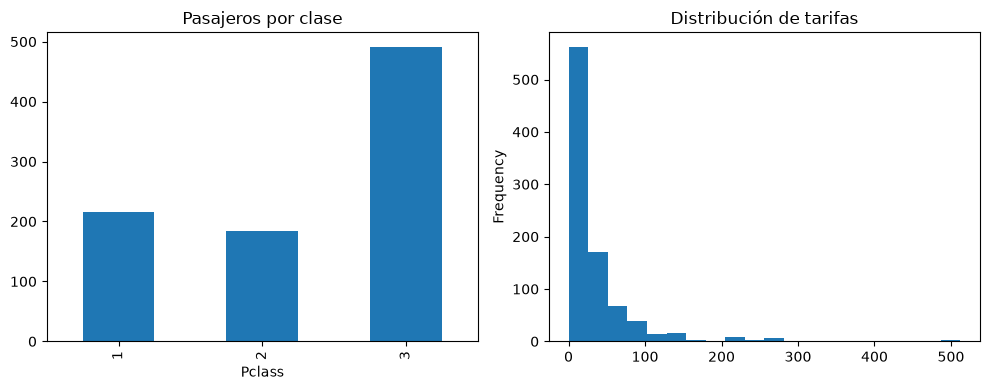

In [95]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
titanic["Pclass"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Pasajeros por clase")
titanic["Fare"].plot(kind="hist", bins=20, ax=axes[1], title="Distribución de tarifas")
plt.tight_layout()
plt.show()

**Parámetros comunes de `Series.plot`/`DataFrame.plot`:** `kind` (`"line"`,
`"bar"`, `"hist"`, `"box"`, `"scatter"`...), `x`/`y` columnas, `ax` ejes de
Matplotlib, `figsize=(ancho, alto)`, `title`, `legend`, `grid`, `alpha`.
Histograma: `bins`; dispersión: `c`/`color`, `s`. Devuelve `Axes`, no un
DataFrame.

## F28 — ¿Cómo comparo una variable numérica entre grupos?

**Pregunta.** «¿Cuál es la tasa de supervivencia por sexo y clase?»

**Cómo se resuelve.** Primero calcula una tabla de resumen con `groupby`; luego
grafica esa tabla. `mean` de una columna 0/1 equivale a proporción de unos. Para
correlaciones selecciona columnas numéricas explícitamente: `corr()` no debe
recibir texto como `Name`/`Sex`.

In [96]:
tasa = titanic.groupby(["Sex", "Pclass"])["Survived"].mean().unstack()
tasa

Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


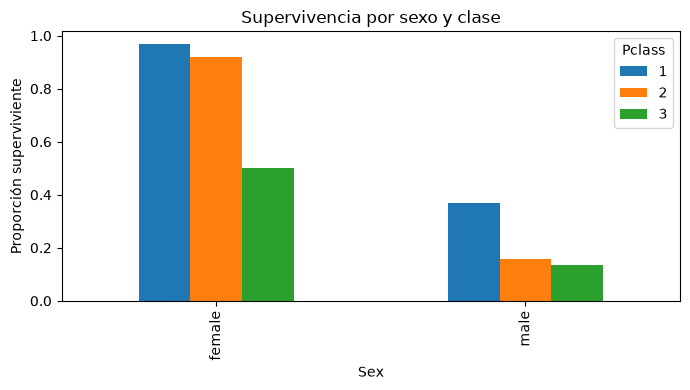

In [97]:
ax = tasa.plot(kind="bar", figsize=(7, 4), ylabel="Proporción superviviente", title="Supervivencia por sexo y clase")
plt.tight_layout()
plt.show()

In [98]:
# Correlación solo de columnas numéricas seleccionadas; evita depender de conversión implícita
numericas = titanic[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]]
numericas.corr()

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


**Parámetros:** `groupby` como en F15; `unstack(level=-1)` pivota un nivel del
índice a columnas; `corr(method="pearson", min_periods=1)` calcula correlación
entre columnas numéricas. La correlación no demuestra causalidad. Para
`seaborn.heatmap(data, annot=False, cmap=...)`, `data` debe ser una tabla
numérica, normalmente el resultado de `corr()`.

## F29 — ¿Cómo se leen `hist`, `boxplot`, `scatter` y `kde`?

**Pregunta.** «¿Qué gráfico me ayuda a ver sesgo, valores extremos o relación?»

**Cómo se resuelve.** Histograma: forma de una variable; caja: mediana, cuartiles
y posibles atípicos; dispersión: relación entre dos variables; KDE: estimación
suavizada de densidad, no cuenta observaciones. Un KDE puede ocultar picos si el
suavizado es excesivo.

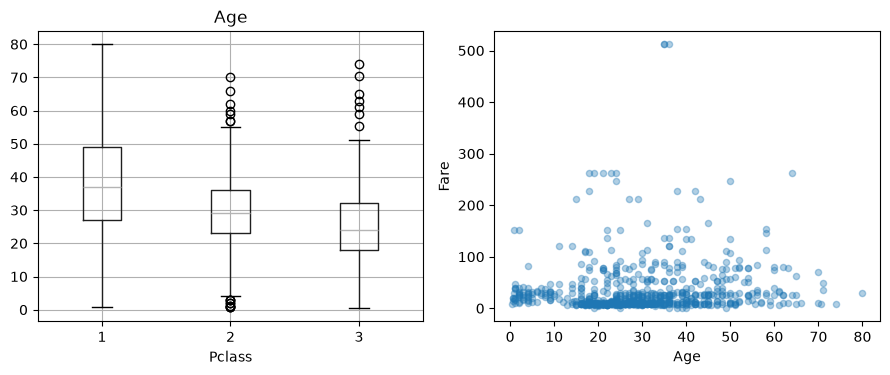

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
titanic.boxplot(column="Age", by="Pclass", ax=axes[0])
titanic.plot(kind="scatter", x="Age", y="Fare", alpha=0.35, ax=axes[1])
fig.suptitle("")
plt.tight_layout()
plt.show()

**Parámetros:** `DataFrame.boxplot(column, by, ax, grid)`; `scatter` requiere
`x` e `y`, y admite `alpha` para transparencia. Para colorear categóricamente
usa Seaborn (`sns.scatterplot(data=df, x=..., y=..., hue=...)`); no pases texto
a `corr` esperando que se convierta mágicamente.

---
# J. Series temporales (cuaderno 09)

Para `resample`, el índice debe ser `DatetimeIndex` y estar ordenado. La
frecuencia es una regla de agrupación temporal, no un simple formato de fecha.

## F30 — ¿Cómo convierto fechas y preparo el índice?

**Pregunta.** «La columna Date es texto y quiero trabajar por mes.»

**Cómo se resuelve.** Convierte con `to_datetime`, valida tipos, usa `set_index`
y ordena el índice. Sin índice temporal no puedes hacer `resample`.

In [100]:
apple = pd.read_csv("datasets/Apple_Stock/appl_1980_2014.csv")
apple["Date"] = pd.to_datetime(apple["Date"], errors="raise")
apple = apple.set_index("Date").sort_index()
print(type(apple.index).__name__, apple.index.is_monotonic_increasing)
apple.head(3)

DatetimeIndex True


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45
1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39


**Parámetros:** `pd.to_datetime(arg, format=None, errors="raise", utc=False)`;
`errors="coerce"` convierte fechas inválidas a `NaT`; `format` fija el patrón.
`set_index(keys, drop=True, verify_integrity=False)`; `sort_index(ascending=True)`.

## F31 — ¿Cómo agrego por mes, calculo ventana móvil y retornos?

**Pregunta.** «Quiero cierre mensual, media de 30 sesiones y rendimiento
acumulado.»

**Cómo se resuelve.** `resample` agrupa por calendario y necesita una reducción
como `last` o `mean`; `rolling` usa una ventana móvil; `pct_change` da cambio
relativo, y `cumprod` compone rendimientos. Distingue retorno diario de retorno
acumulado.

In [101]:
# Frecuencia mensual al inicio de cada mes: MS evita el alias antiguo M
monthly = apple["Adj Close"].resample("MS").last()
monthly.head()

Date
1980-12-01    0.53
1981-01-01    0.44
1981-02-01    0.41
1981-03-01    0.38
1981-04-01    0.44
Freq: MS, Name: Adj Close, dtype: float64

In [102]:
close = apple["Adj Close"]
rolling_30 = close.rolling(window=30, min_periods=30).mean()
returns = close.pct_change(fill_method=None)
cumulative = (1 + returns.fillna(0)).cumprod() - 1
print("media móvil reciente:\n", rolling_30.tail(3))
print("retorno acumulado final:", round(cumulative.iloc[-1] * 100, 2), "%")

media móvil reciente:
 Date
2014-07-03    91.494333
2014-07-07    91.801667
2014-07-08    92.055667
Name: Adj Close, dtype: float64
retorno acumulado final: 21088.89 %


**Parámetros:** `resample(rule, closed=None, label=None, origin=...)`; `"MS"`
es inicio de mes y funciona en 2.x/3.x. Para cierre de mes usa `"ME"` (no el
alias antiguo `"M"`, renombrado en pandas 3). En el entorno pandas 2.3.3 de
este curso, `"ME"` lanza además un `DeprecationWarning` interno de NumPy; por
eso este ejemplo elige `"MS"` para un recorrido sin warnings.
Después se necesita `.last()`, `.mean()`, etc. `rolling(window, min_periods)`;
`pct_change(periods=1, fill_method=None)` calcula cambio relativo (usar
`fill_method=None` explícito para evitar rellenado implícito de huecos);
`cumprod(skipna=True)` acumula el producto. `shift` desplaza valores por filas.

## F32 — ¿Cómo sé si hay fechas duplicadas y cuánto dura la serie?

**Pregunta.** «¿Hay dos cotizaciones para la misma fecha? ¿Cuántos días cubre
el dataset?»

**Cómo se resuelve.** `index.duplicated` detecta etiquetas repetidas; resta las
fechas extremas para obtener duración. No elimines duplicados sin decidir qué
observación conservar.

In [103]:
print("fechas duplicadas:", apple.index.duplicated().sum())
duracion = apple.index.max() - apple.index.min()
print("duración:", duracion.days, "días")

fechas duplicadas: 0
duración: 12261 días


**Parámetros:** `Index.duplicated(keep="first")` (`"last"` o `False` para todas);
`Timedelta.days` atributo entero. Para meses calendario usa `resample("ME")` o
`PeriodIndex`; el alias antiguo `"M"` se renombró a `"ME"`. Para fin de mes
hábil, `"BM"` se renombró a `"BME"`. En el entorno pandas 2.3.3 usado aquí,
`ME`/`BME` provocan además un `DeprecationWarning` interno de NumPy; `"MS"`
(inicio de mes) no lo provoca. Dividir días entre 30 solo da una aproximación.

---
## F33 — ¿Cómo sumo una columna y cuento valores distintos?

**Pregunta.** «¿Cuántos artículos se pidieron en total? ¿Cuántos productos
únicos se vendieron?»

**Cómo se resuelve.** `sum` agrega valores numéricos; `nunique` cuenta distintos
sin tener que construir primero un conjunto. `unique()` devuelve los valores,
`nunique()` devuelve el número.

In [104]:
print("unidades pedidas:", chipo["quantity"].sum())
print("productos distintos:", chipo["item_name"].nunique())
print("órdenes distintas:", chipo["order_id"].nunique())

# Ingreso por línea = cantidad x precio; después total medio por orden
precios = pd.to_numeric(chipo["item_price"].str.replace("$", "", regex=False).str.strip(), errors="coerce")
ventas = chipo.assign(item_price=precios)
ventas = ventas.assign(revenue=ventas["quantity"] * ventas["item_price"])
revenue_por_orden = ventas.groupby("order_id")["revenue"].sum()
print("ingreso total:", round(ventas["revenue"].sum(), 2))
print("ingreso medio por orden:", round(revenue_por_orden.mean(), 2))

unidades pedidas: 4972
productos distintos: 50
órdenes distintas: 1834
ingreso total: 39237.02
ingreso medio por orden: 21.39


**Parámetros:** `sum(axis=0, skipna=True, min_count=0)`; `nunique(dropna=True)`;
`unique()` devuelve array en orden de aparición. Para sumar ingresos por orden,
primero calcula el ingreso de cada fila y agrupa por `order_id` (F17/F24).

## F34 — ¿Asigno con `df["col"] = ...` o con `assign`?

**Pregunta.** «¿Por qué hay dos maneras de añadir o sustituir una columna?»

**Cómo se resuelve.** `df["col"] = valores` modifica el DataFrame existente;
`assign(col=valores)` devuelve una copia modificada y permite encadenar. Ambos
alinean una Serie por índice. Elige uno por intención y sé consistente.

In [105]:
# Asignación directa (muta el objeto)
directo = pokemon.copy()
directo["Region"] = "Kanto"

# assign (devuelve un nuevo DataFrame; el original queda igual)
encadenado = pokemon.assign(Region="Kanto", HP_doble=pokemon["HP"] * 2)
print("Region en original:", "Region" in pokemon.columns)
print(directo.head(2))
print(encadenado.head(2))

Region en original: False
         Name   Type  HP Region
0   Bulbasaur  Grass  45  Kanto
1  Charmander   Fire  39  Kanto
         Name   Type  HP Region  HP_doble
0   Bulbasaur  Grass  45  Kanto        90
1  Charmander   Fire  39  Kanto        78


**Parámetros:** `assign(**kwargs)` recibe nombres de columnas como argumentos
con nombre; los valores pueden ser escalares, arrays o Series (estas últimas se
alinean por índice). En ambos casos las listas/arrays deben tener el mismo
número de filas.

---
## F35 — ¿Cómo selecciono columnas por posición o equipos por texto?

**Pregunta.** «Quiero las primeras siete columnas, quitar las últimas tres o
buscar equipos cuyo nombre empieza por G.»

**Cómo se resuelve.** Para columnas por posición se usa `iloc[:, slice]`; el
límite final queda excluido como en una lista. Para texto, el accesor `.str`
proporciona `startswith`; para una lista concreta, `isin` crea la máscara.

In [106]:
# Posiciones 0–6: el 7 queda excluido
primeras_siete = euro12.iloc[:, 0:7]
print(primeras_siete.shape)
# Todas menos las últimas tres
euro_sin_tres = euro12.iloc[:, :-3]
print(euro_sin_tres.shape)

(16, 7)
(16, 32)


In [107]:
# Filtro de texto; na=False hace explícito que un nombre nulo no coincide
empiezan_g = euro12.loc[euro12["Team"].str.startswith("G", na=False), ["Team", "Goals"]]
empiezan_g

,Team,Goals
5,Germany,10
6,Greece,5


In [108]:
# Lista de equipos: isin produce una máscara booleana
elegidos = euro12.loc[euro12["Team"].isin(["Spain", "Italy", "Germany"]), ["Team", "Shooting Accuracy"]]
elegidos

,Team,Shooting Accuracy
5,Germany,47.8%
7,Italy,43.0%
13,Spain,55.9%


**Parámetros:** `.iloc[filas, columnas]` usa posiciones enteras y slices con fin
excluido; `Series.str.startswith(pat, na=False)` recibe prefijo(s),
`case=True` por defecto; `Series.isin(values)` recibe una lista/Serie/conjunto.
Las columnas por nombre siguen siendo más robustas a cambios en el orden.

---
# Mapa de errores frecuentes

| Síntoma | Causa | Solución |
|---|---|---|
| `KeyError: 'Age '` | Espacio o mayúscula en el nombre | `list(df.columns)` y copiar el nombre exacto |
| `KeyError: ('Age', 'Fare')` | Tupla en vez de lista | `df[["Age", "Fare"]]` |
| `ValueError: truth value of a Series is ambiguous` | `and` / `or` | `&` / `\|` con paréntesis |
| `TypeError: unsupported operand type(s) for &` | Falta paréntesis en la comparación | `(df["a"] > 1) & (df["b"] < 2)` |
| Columna entera a `NaN` al asignar | Índices distintos | `.to_numpy()` o construir la Serie con `df.index` |
| El cambio «no se guarda» | El método devuelve copia | Reasignar: `df = df.drop(...)` |
| `df["Age"][mask] = 5` no hace nada | Indexación encadenada | `df.loc[mask, "Age"] = 5` |
| `.loc[0:2]` devuelve 3 filas | `loc` incluye el extremo | `.iloc[0:3]` para posiciones |
| `AttributeError: 'DataFrame' object has no attribute 'str'` | `.str` sobre el DataFrame | Aplicarlo a la columna: `df["col"].str...` |
| `FutureWarning` por `inplace` | `inplace` deprecado | Reasignar el resultado |

## Qué NO aparece en este cuaderno, y por qué

- **`applymap`**: deprecado desde pandas 2.1. Se usa `DataFrame.map`.
- **`df.append`**: eliminado en pandas 2.0. Se usa `pd.concat`.
- **`fillna(method="ffill")`**: deprecado. Se usa `df.ffill()`.
- **`inplace=True`**: deprecado en pandas 3.1 en los métodos que devuelven copia.

## Siguiente bloque

Falta el bloque de **agrupación, combinación, estadística, visualización y
series temporales** (cuadernos 03, 04, 05, 06, 07, 09). Se añadirá en cuanto
este bloque esté validado en clase.